<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/Actividad_EDA_predictivo_bank_marketing_274705.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Victor Joshua Hernandez Ramon

**Matrícula:** 274705

**Fecha:**  11/10/2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |Un contacto telefonico de una campaña de marketing con un cliente bancario. |
| ¿Qué se predice? |Si el cliente suscribira o no el deposito a plazo. |
| ¿Qué tipo de problema es? |Clasificacion binaria. |
| ¿En qué momento se haría la predicción y qué información existiría entonces? |Antes de realizar la llamada telefonica en una campaña nueva. Existiría informacion, historial previo e indicadores socioeconómicos actuales. |
| ¿Qué columnas no deberían usarse como características y por qué? |`duration`. La duración solo se conoce después de finalizar la llamada. Usarla provocaria fuga de informacion. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Espero que la gran mayoría de los clientes no contraten, estimando una tasa de éxito baja (entre el 10% y el 15%), lo cual es común en campañas en frío de telemarketing.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

No espero encontrar valores NaN porque las instrucciones mencionan que los datos faltantes se codificaron con la palabra unknown. Espero encontrar 'unknown' principalmente en variables de información personal o financiera donde los clientes suelen ser más reservados.

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.
print("Filas y columnas:", df.shape)
print("\nTipos de datos:\n", df.dtypes)
print("\nValores unicos por columna (de menor a mayor):\n", df.nunique().sort_values())

Filas y columnas: (41188, 21)

Tipos de datos:
 age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Valores únicos por columna (de menor a mayor):
 contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      2

In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.
print("Total de NaN explicitos en el conjunto:", df.isna().sum().sum())

print("\nConteo de 'unknown' en variables categoricas:")
unknown_counts = (df[categoricas] == 'unknown').sum()
unknown_counts = unknown_counts[unknown_counts > 0]
print(unknown_counts)

print("\nPorcentaje de 'unknown' sobre el total de filas:")
print(round((unknown_counts / df.shape[0]) * 100, 2))

Total de NaN explícitos en el conjunto: 0

Conteo de 'unknown' en variables categóricas:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

Porcentaje de 'unknown' sobre el total de filas:
job           0.80
marital       0.19
education     4.20
default      20.87
housing       2.40
loan          2.40
dtype: float64


In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("Numero de filas completamente duplicadas:", df.duplicated().sum())

Número de filas completamente duplicadas: 12


In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.
pdays_999 = (df['pdays'] == 999).sum()
print(f"Filas con pdays == 999: {pdays_999} ({(pdays_999/df.shape[0])*100:.2f}%)")

print("\npoutcome vs (previous == 0):")
print(pd.crosstab(df['poutcome'], df['previous'] == 0))

print("\npoutcome vs (pdays == 999):")
print(pd.crosstab(df['poutcome'], df['pdays'] == 999))

Filas con pdays == 999: 39673 (96.32%)

poutcome vs (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

poutcome vs (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.
print(f"Edad: Minima = {df['age'].min()}, Máxima = {df['age'].max()}")
print("Llamadas con duration == 0:", (df['duration'] == 0).sum())
print(f"Campaign: Minima = {df['campaign'].min()}, Máxima = {df['campaign'].max()}")
print("Filas con previous negativo:", (df['previous'] < 0).sum())

Edad: Mínima = 17, Máxima = 98
Llamadas con duration == 0: 4
Campaign: Mínima = 1, Máxima = 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

No hay NaN, pero hay varias columnas con la etiqueta 'unknown'. Se detectaron 12 filas 100% duplicadas. La variable pdays con valor 999 representa al 96% de la base de datos y cruza logicamente de manera perfecta con previous == 0 y poutcome == 'nonexistent'. Estos no son errores, sino características de la captura. Existen edades en rango (17 a 98) y hay 4 contactos con duracion de 0 segundos qur pueden ser llamadas colgadas inmediatamente.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

Lo trataria como una categoria valida y no eliminaria las filas. El que sea imposible determinar el historial de creditos de un cliente podría revelar algo importante sobre su perfil de riesgo. Imputar este dato con el mas frecuente causaria que se pierda esta posible señal.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

La proporción de contratación sera igual en entrenamiento y prueba, porque utilizaremos una division estratificada.

In [7]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.
entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df['y'], random_state=42)

ent = entrenamiento.copy()
ent['suscribe'] = (ent['y'] == 'yes').astype(int)

print(f"Tamaño de entrenamiento: {ent.shape[0]} | Tamaño de prueba: {prueba.shape[0]}")
print("Porcentaje de contratación en entrenamiento:", round((ent['suscribe'] == 1).mean() * 100, 2), "%")
print("Porcentaje de contratación en prueba:", round((prueba['y'] == 'yes').mean() * 100, 2), "%")

Tamaño de entrenamiento: 32950 | Tamaño de prueba: 8238
Porcentaje de contratación en entrenamiento: 11.27 %
Porcentaje de contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [8]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

Ambos conjuntos registran exactamente la misma tasa (11.27%), garantizando que el modelo aprendera de una muestra balanceada y la validacion sera justa.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Un modelo que diga siempre 'no' tendría una exactitud de alrededor del 88.7%, debifo al desbalance de clases.

     clientes  porcentaje
y                        
no      29238        88.7
yes      3712        11.3

Razón (mayoritaria / minoritaria): 7.88
Exactitud de responder siempre 'no': 88.7 %


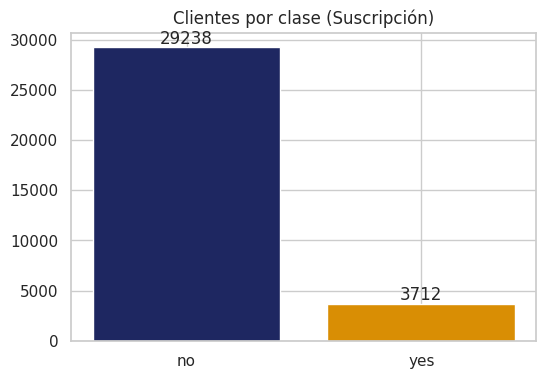

In [9]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.
conteo_clases = ent['y'].value_counts()
porcentaje_clases = (ent['y'].value_counts(normalize=True) * 100).round(1)

print(pd.DataFrame({"clientes": conteo_clases, "porcentaje": porcentaje_clases}))
print("\nRazón (mayoritaria / minoritaria):", round(conteo_clases['no'] / conteo_clases['yes'], 2))
print("Exactitud de responder siempre 'no':", porcentaje_clases['no'], "%")

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(conteo_clases.index, conteo_clases.values, color=[COLORES_CLASE[x] for x in conteo_clases.index])
ax.bar_label(barras)
ax.set_title("Clientes por clase (Suscripción)")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

La metrica de exactitud engañaria el rendimiento real del modelo predictivo porque predecir la clase dominante ya te otorga 88.7% de precision.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

"Espero que duration difiera mas. Quizas los indicadores econonicos tambien."

Medianas por clase:
      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1            93.9          -41.8        4.9       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8            93.2          -40.4        1.3       5099.1


/tmp/ipykernel_1284/1285174942.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="duration", palette=COLORES_CLASE, ax=ejes[0]).set_title("duration")
/tmp/ipykernel_1284/1285174942.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="age", palette=COLORES_CLASE, ax=ejes[1]).set_title("age")
/tmp/ipykernel_1284/1285174942.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x="y", y="euribor3m", palette=COLORES_CLASE, ax=ejes[2]).set_title("euribor3m")


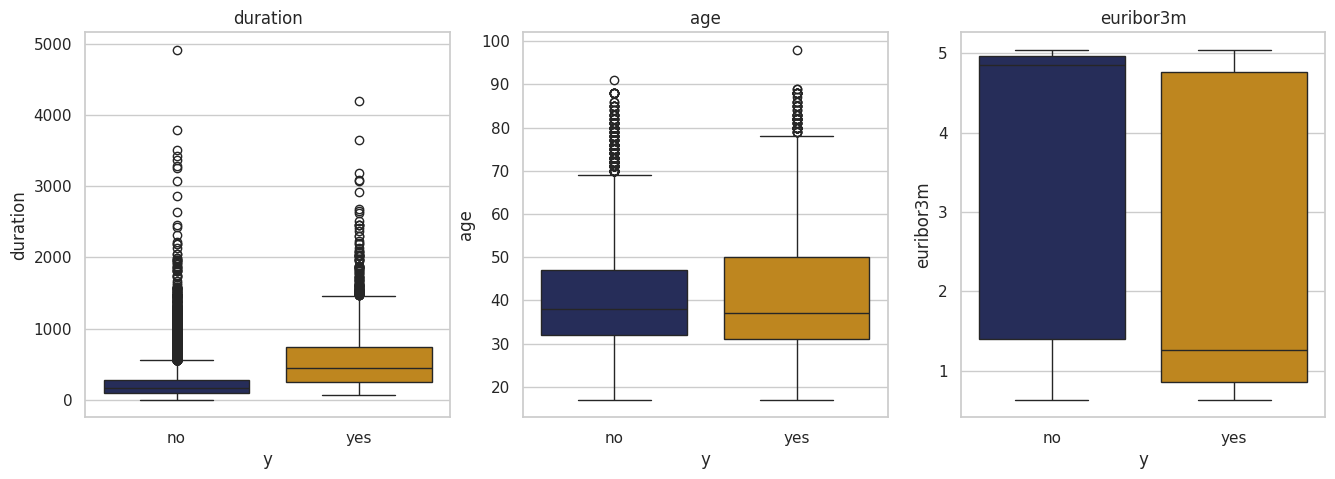

In [10]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
print("Medianas por clase:")
print(ent.groupby('y')[numericas].median().round(1))

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=ent, x="y", y="duration", palette=COLORES_CLASE, ax=ejes[0]).set_title("duration")
sns.boxplot(data=ent, x="y", y="age", palette=COLORES_CLASE, ax=ejes[1]).set_title("age")
sns.boxplot(data=ent, x="y", y="euribor3m", palette=COLORES_CLASE, ax=ejes[2]).set_title("euribor3m")
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

Se observa que variables macroeconomicas (como euribor3m) y duration separan notablemente a las clases, mostrando diferentes medianas. Variables como age o campaign se distribuyen de forma similar, siendo menos informativas solas.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Las llamadas o variables de conteo como campaign tendran bastantes valores fuera del limite de Tukey.

In [11]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1
inferior = q1 - 1.5 * ric
superior = q3 + 1.5 * ric

print("Registros fuera de los límites de Tukey (por variable):")
print(((ent[numericas] < inferior) | (ent[numericas] > superior)).sum())

Registros fuera de los límites de Tukey (por variable):
age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

No eliminaría ningún registro atípico en este momento porque en variables como edad o duracion de la llamada, una 'anomalía' Tukey dice que estos casos son normales en el mundo real. Modificarlos podria alterar valores imporantes.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Espero que la transformacion de logaritmo (np.log1p) reduzca mucho mas la asimetría de campaign, ya que es útil para variables de conteo que tienden hacia la derecha.

Comparativa de Asimetría:
           original  raiz_cuadrada  logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35


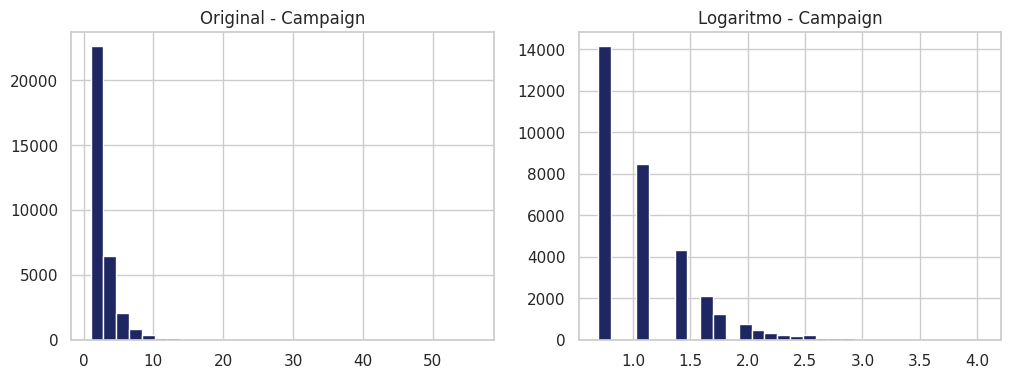

In [12]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.
cols_asim = ['age', 'duration', 'campaign']
df_asim = pd.DataFrame({
    'original': ent[cols_asim].skew(),
    'raiz_cuadrada': np.sqrt(ent[cols_asim]).skew(),
    'logaritmo': np.log1p(ent[cols_asim]).skew()
}).round(2)
print("Comparativa de Asimetría:\n", df_asim)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(ent['campaign'], bins=30, color=AZUL)
ejes[0].set_title('Original - Campaign')
ejes[1].hist(np.log1p(ent['campaign']), bins=30, color=AZUL)
ejes[1].set_title('Logaritmo - Campaign')
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

Para campaign, su asimetría original es altísima (4.78). El logaritmo logró compactar la cola larga fuertemente a 1.15. Si el modelo a entrenar no está basado en árboles, recomendaría transformar campaign logarítmicamente.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaría que el resultado de la campaña anterior (poutcome igual a success) o los meses del año tengan las mayores tasas de contratacion. En cambio variables como day_of_week o tener un prestamo hipotecario (housing) probablemente casi no separen las clases.

In [13]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.
print("Número de categorías por característica:\n", ent[categoricas].nunique().sort_values())
print("\nTasa de contratación global en ent:", round(ent['suscribe'].mean() * 100, 1), "%")

Número de categorías por característica:
 contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa de contratación global en ent: 11.3 %


In [14]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.
largo = ent[categoricas].astype(str).assign(suscribe=ent["suscribe"]).melt(
    id_vars="suscribe", var_name="caracteristica", value_name="categoria"
)
tasas = largo.groupby(["caracteristica", "categoria"])["suscribe"].agg(clientes="count", tasa_contratacion="mean")
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

print("12 categorías con mayor tasa:\n", tasas.sort_values("tasa_contratacion", ascending=False).head(12))
print("\n8 categorías con menor tasa:\n", tasas.sort_values("tasa_contratacion", ascending=False).tail(8))

print("\nDetalle Default:\n", tasas.loc["default"])
print("\nDetalle Housing:\n", tasas.loc["housing"])
print("\nDetalle Loan:\n", tasas.loc["loan"])
print("\nDetalle Day of Week:\n", tasas.loc["day_of_week"])

12 categorías con mayor tasa:
                            clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7

8 categorías con menor tasa:
                             clientes  tasa_contratacion
caracteristica categoria                               
education      basic.6y         1865                8.4


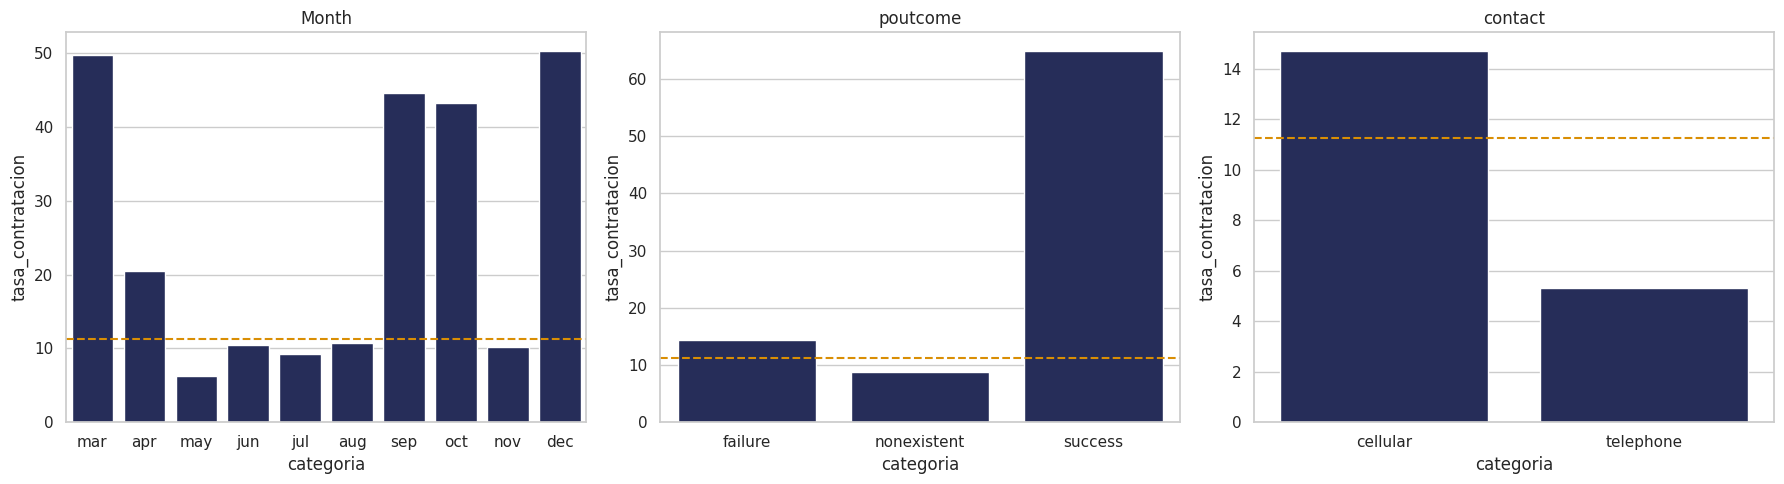

In [15]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.
# E3. Gráficas de tasa de contratación.
tasa_global = ent['suscribe'].mean() * 100
orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

# Plot Month
meses_df = tasas.loc["month"].reindex(orden_meses).reset_index()
sns.barplot(data=meses_df, x="categoria", y="tasa_contratacion", color=AZUL, ax=ejes[0])
ejes[0].axhline(tasa_global, color=NARANJA, linestyle='--')
ejes[0].set_title('Month')

# Plot poutcome
pout_df = tasas.loc["poutcome"].reset_index()
sns.barplot(data=pout_df, x="categoria", y="tasa_contratacion", color=AZUL, ax=ejes[1])
ejes[1].axhline(tasa_global, color=NARANJA, linestyle='--')
ejes[1].set_title('poutcome')

# Plot contact
cont_df = tasas.loc["contact"].reset_index()
sns.barplot(data=cont_df, x="categoria", y="tasa_contratacion", color=AZUL, ax=ejes[2])
ejes[2].axhline(tasa_global, color=NARANJA, linestyle='--')
ejes[2].set_title('contact')

plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

Variables como month o poutcome ('success' tiene > 65% de éxito) son fuertes predictores. Por el contrario, day_of_week, housing o loan varían décimas alrededor del 11.3% global, por lo que casi no separan las clases.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

La categoría unknown en default tiene una tasa (~5%) inferior al no endeudamiento de tarjeta, comportándose como perfil distinto. Para yes en default hay solo ~3 clientes, así que su tasa de '0.0%' es simplemente falta de muestra y estadísticamente irrelevante.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Euribor y los índices de precios deberían estar correlacionados fuertemente, dada la naturaleza entrelazada de los indicadores macroeconómicos.

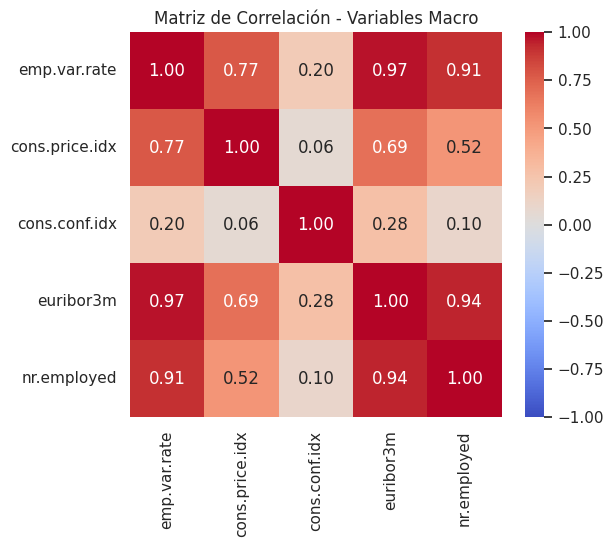

In [16]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
plt.figure(figsize=(6, 5))
matriz_corr = ent[macro].corr()
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación - Variables Macro")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

Existe una fuerte multicolinealidad. emp.var.rate tiene una correlación de 0.97 con euribor3m y 0.91 con nr.employed. Esto puedo ocasionar problemas en modelos lineales.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [17]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
print(ent.groupby("y")["duration"].describe().round(1))

       count   mean    std   min    25%    50%    75%     max
y                                                            
no   29238.0  221.1  208.3   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.4  397.5  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

No debe incluirse duration. Su valor es '0' o minimo antes de la llamada, solo al terminar se genera un registro. Incluirla causaria fuga de informacion, porque en un entorno real no tienes ese tiempo registrado previamente.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

Dividir al azar mezcla tiempos, el banco usara el modelo en el futuro. Para que la metrica de test sea realista, lo ideal seria hacer un split por tiempo, donde los meses mas recientes sean de prueba para simular correctamente una campaña.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|La variable duration es un elemento post-evento no disponible. |Eliminar la columna duration del conjunto final. |Preprocesamiento |
|Alta correlación entre emp.var.rate y euribor3m (r=0.97). |Eliminar 1 de las variables colineales para evitar redundancia. |Preprocesamiento |
|Existen faltantes encubiertos bajo el texto "unknown". |Mantener la palabra "unknown" como categoría separada, no imputar. |Preprocesamiento |
|La clase de éxito (y="yes") solo conforma el 11.27% del set. |Implementar balanceo de clases y usar métricas de clase menor. |Modelado / Evaluación |
|Existen categorías nulas o vacías (ej: Default yes con 3 registros). |No descartar las variables, pero agrupar o ser cautelosos con modelos lineales categóricos. |Preprocesamiento |
|La asimetría para campaign es altísima (4.78). |Transformar con logaritmo natural np.log1p en caso de usar Regresión Logística. |Preprocesamiento / Modelos |
|Las variables housing y loan varían <0.5% respecto a la media global de éxito (11.3%). |Considerar descartar estas variables en procesos de selección de características. |Preprocesamiento |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

Se uso el conjunto total df para detectar problemas estructurales (conteos de Nulos, Tipos de datos, rangos incoherentes) en la parte B, porque conocerlos no influye en los valores del modelo. A partir de la parte C, todas las agregaciones estadísticas y relaciones con el objetivo se separaron hacia entrenamiento, previniendo así afectar el dataset de validación.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

Si se hubiesen calculado por ejemplolos  Límites de Tukey, se inyectaria información de varianza del futuro al modelo causando un data leakeage. Esto causaría que las métricas de evaluación del modelo aparezcan falsamente optimistas, y afectando la precision real.